# Lecture 3 — Line Charts: CO₂ Emissions (2000–2022)

**Tasks**
1. Compare CO₂ emissions per capita across all 15 countries, highlighting one country.
2. Compare total CO₂ emissions over time for Asian countries, highlighting one country.

The charts use the Our World in Data CO₂ dataset. Context countries are shown in light grey; the highlighted country is labelled at the end of its line.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Try the course's expected path first, then common local/Kaggle upload paths.
candidate_paths = [
    Path("../data/co2_emissions.csv"),
    Path("data/co2_emissions.csv"),
    Path("/kaggle/input/datasets/owid-co2-data/owid-co2-data.csv"),
    Path("/mnt/data/owid-co2-data.csv"),
    Path("owid-co2-data.csv"),
]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "CO2 dataset not found. Place co2_emissions.csv in ../data/ or data/, "
        "or add the uploaded OWID CSV to the notebook environment."
    )

raw = pd.read_csv(data_path)
print(f"Loaded: {len(raw):,} rows from {data_path}")
print("Available columns:", ", ".join(raw.columns[:12]))

# Standardise the full OWID dataset and the smaller class-exercise dataset
# into the same column names.
if {"country", "year", "co2", "co2_per_capita"}.issubset(raw.columns):
    df = raw.rename(columns={
        "country": "Country",
        "year": "Year",
        "co2": "CO2_Mt",
        "co2_per_capita": "CO2_per_capita",
    })
elif {"Country", "Year", "CO2_Mt", "CO2_per_capita"}.issubset(raw.columns):
    df = raw.copy()
else:
    raise ValueError("Dataset must contain country/year/co2/co2_per_capita or the class exercise column names.")

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["CO2_Mt"] = pd.to_numeric(df["CO2_Mt"], errors="coerce")
df["CO2_per_capita"] = pd.to_numeric(df["CO2_per_capita"], errors="coerce")
countries = [
    "United States", "China", "India", "Germany", "United Kingdom",
    "France", "Brazil", "Japan", "Canada", "Australia",
    "South Korea", "Russia", "South Africa", "Mexico", "Indonesia"
]
df = df[df["Country"].isin(countries) & df["Year"].between(2000, 2022)].copy()
df = df.sort_values(["Country", "Year"])
print(f"Exercise subset: {df['Country'].nunique()} countries | {int(df['Year'].min())}–{int(df['Year'].max())} | {len(df)} rows")


Loaded: 50,411 rows from /mnt/data/owid-co2-data.csv
Available columns: country, year, iso_code, population, gdp, cement_co2, cement_co2_per_capita, co2, co2_growth_abs, co2_growth_prct, co2_including_luc, co2_including_luc_growth_abs
Exercise subset: 15 countries | 2000–2022 | 345 rows


## Task 1 — CO₂ emissions per capita across all 15 countries

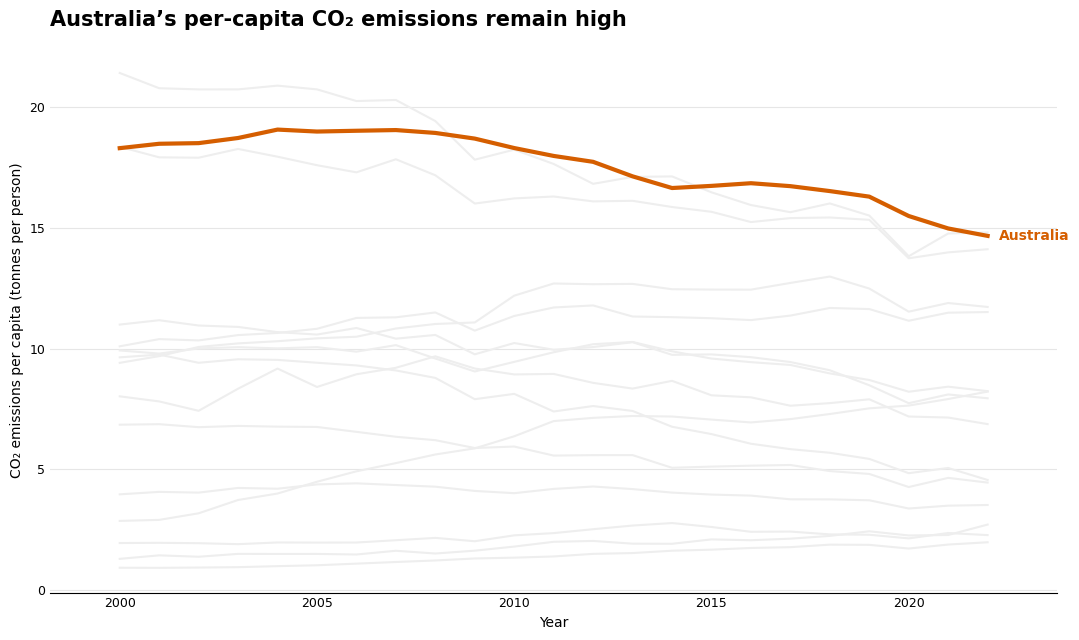

Insight (2022): United States has the highest per-capita emissions among the 15 countries at 14.8 tonnes per person.
Australia: 18.3 tonnes/person in 2000 → 14.7 in 2022.


In [2]:
# Highlight Australia: its per-capita emissions remain among the highest in this group.
highlight_country = "Australia"
fig, ax = plt.subplots(figsize=(11, 6.5))

for country, group in df.groupby("Country"):
    group = group.dropna(subset=["CO2_per_capita"])
    if country == highlight_country:
        continue
    ax.plot(group["Year"], group["CO2_per_capita"], color="#EEEEEE", linewidth=1.5, zorder=1)

highlight = df[df["Country"] == highlight_country].dropna(subset=["CO2_per_capita"]).sort_values("Year")
ax.plot(highlight["Year"], highlight["CO2_per_capita"], color="#D55E00", linewidth=3, zorder=3)
if not highlight.empty:
    last = highlight.iloc[-1]
    ax.annotate(
        highlight_country, (last["Year"], last["CO2_per_capita"]),
        xytext=(8, 0), textcoords="offset points", va="center",
        fontsize=10, fontweight="bold", color="#D55E00"
    )

ax.set_title("Australia’s per-capita CO₂ emissions remain high", loc="left", fontsize=15, fontweight="bold", pad=16)
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ emissions per capita (tonnes per person)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=9)
ax.margins(x=0.08)
plt.tight_layout()
plt.show()

latest = df[df["Year"] == df["Year"].max()].dropna(subset=["CO2_per_capita"]).sort_values("CO2_per_capita", ascending=False)
print(f"Insight ({int(df['Year'].max())}): {latest.iloc[0]['Country']} has the highest per-capita emissions among the 15 countries at {latest.iloc[0]['CO2_per_capita']:.1f} tonnes per person.")
print(f"{highlight_country}: {highlight['CO2_per_capita'].iloc[0]:.1f} tonnes/person in 2000 → {highlight['CO2_per_capita'].iloc[-1]:.1f} in {int(highlight['Year'].iloc[-1])}.")


## Task 2 — Total CO₂ emissions for Asian countries

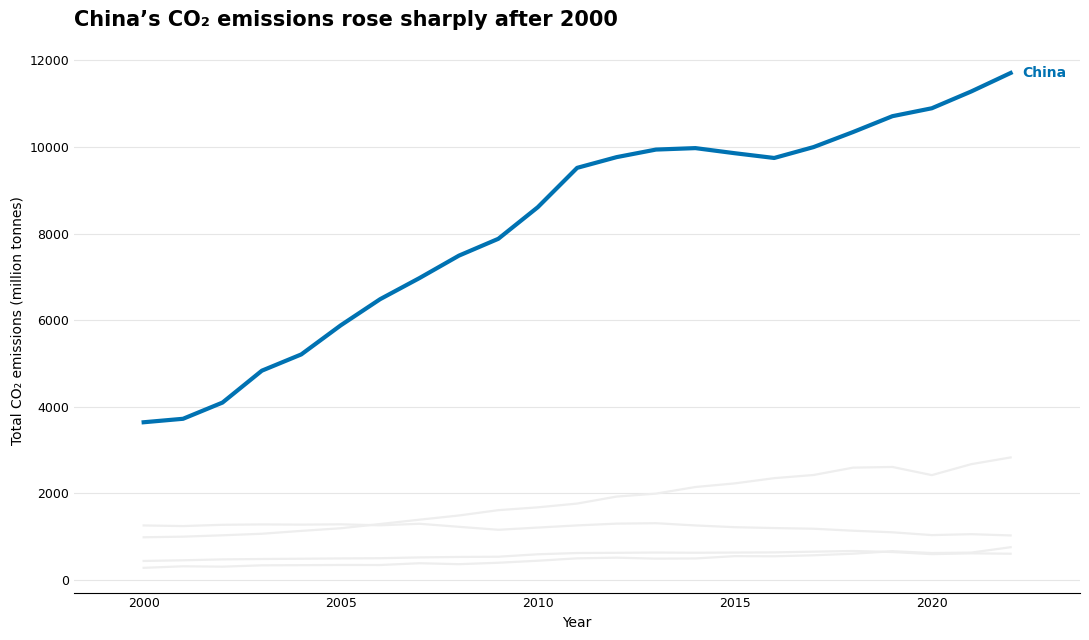

Insight: China’s total CO₂ emissions changed from 3,644 Mt in 2000 to 11,712 Mt in 2022.


In [3]:
# Asian countries in this exercise dataset: China, India, Japan, South Korea and Indonesia.
asian_countries = ["China", "India", "Japan", "South Korea", "Indonesia"]
highlight_country = "China"
asia = df[df["Country"].isin(asian_countries)].copy()

fig, ax = plt.subplots(figsize=(11, 6.5))
for country, group in asia.groupby("Country"):
    group = group.dropna(subset=["CO2_Mt"])
    if country == highlight_country:
        continue
    ax.plot(group["Year"], group["CO2_Mt"], color="#EEEEEE", linewidth=1.6, zorder=1)

highlight = asia[asia["Country"] == highlight_country].dropna(subset=["CO2_Mt"]).sort_values("Year")
ax.plot(highlight["Year"], highlight["CO2_Mt"], color="#0072B2", linewidth=3, zorder=3)
if not highlight.empty:
    last = highlight.iloc[-1]
    ax.annotate(
        highlight_country, (last["Year"], last["CO2_Mt"]),
        xytext=(8, 0), textcoords="offset points", va="center",
        fontsize=10, fontweight="bold", color="#0072B2"
    )

ax.set_title("China’s CO₂ emissions rose sharply after 2000", loc="left", fontsize=15, fontweight="bold", pad=16)
ax.set_xlabel("Year")
ax.set_ylabel("Total CO₂ emissions (million tonnes)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=9)
ax.margins(x=0.08)
plt.tight_layout()
plt.show()

start = highlight.iloc[0]
end = highlight.iloc[-1]
print(f"Insight: China’s total CO₂ emissions changed from {start['CO2_Mt']:,.0f} Mt in {int(start['Year'])} to {end['CO2_Mt']:,.0f} Mt in {int(end['Year'])}.")


### Notes
- Each chart includes all relevant countries as requested; non-highlighted lines use `#EEEEEE`.
- Country names are labelled directly at the end of the highlighted line, so no legend is needed.
- The notebook contains saved chart outputs. If you change the dataset, rerun all cells and save the notebook to update the figures.